In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
import warnings; warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid'); pd.options.display.float_format='{:,.2f}'.format
pd.options.display.max_columns=30

df = pd.read_excel('Mobile.xlsx', sheet_name='Sales')
print(df.shape); df.head()

(3114, 11)


,Brands,Models,Colors,Mobile,Memory,Storage,Selling Price,Original Price,Discount,Rating,R
0,SAMSUNG,GALAXY M31S,Mirage Black,SAMSUNG GALAXY M31S,8,128,19330,20999,1669,4.30,5
1,Nokia,3.20,Steel,Nokia 3.2,2,16,10199,10199,0,3.80,4
2,realme,C2,Diamond Black,realme C2,2,89,6999,7999,1000,4.40,5
3,Infinix,Note 5,Ice Blue,Infinix Note 5,4,64,12999,12999,0,4.20,5
4,Apple,iPhone 11,Black,Apple iPhone 11,4,64,49900,49900,0,4.60,5


## 0. Data understanding & cleaning

In [2]:
df.info()
print('\nMissing values:\n', df.isna().sum().sum())
print('Exact duplicate rows:', df.duplicated().sum())
print('Negative discounts:', (df['Discount']<0).sum())
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 3114 entries, 0 to 3113
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Brands          3114 non-null   str    
 1   Models          3114 non-null   object 
 2   Colors          3114 non-null   str    
 3   Mobile          3114 non-null   str    
 4   Memory          3114 non-null   object 
 5   Storage         3114 non-null   int64  
 6   Selling Price   3114 non-null   int64  
 7   Original Price  3114 non-null   int64  
 8   Discount        3114 non-null   int64  
 9   Rating          3114 non-null   float64
 10  R               3114 non-null   int64  
dtypes: float64(1), int64(5), object(2), str(3)
memory usage: 267.7+ KB

Missing values:
 0
Exact duplicate rows: 108
Negative discounts: 1


,count,mean,std,min,25%,50%,75%,max
Storage,"3,114.00",88.83,92.23,1.00,32.00,64.00,128.00,512.00
Selling Price,"3,114.00","26,436.63","30,066.89","1,000.00","9,990.00","15,000.00","28,999.00","179,900.00"
Original Price,"3,114.00","28,333.47","31,525.60","1,000.00","10,030.25","16,889.50","31,500.00","189,999.00"
Discount,"3,114.00","1,896.85","5,337.13","-8,000.00",0.00,0.00,"2,000.00","75,000.00"
Rating,"3,114.00",4.24,0.27,2.30,4.10,4.30,4.40,5.00
R,"3,114.00",4.80,0.41,3.00,5.00,5.00,5.00,5.00


**Observations & cleaning decisions**
- `Memory` (RAM) mixes units: values such as 512 / 768 / 32 / 64 on old 4 MB-storage feature phones are **MB**, not GB. Any value > 16 (or ≥ the storage size) is treated as MB and converted to GB (÷1024). 
- `Storage` is in GB.
- One row (Lenovo A6000 Plus) has a blank `Memory` value and is dropped.
- Duplicate rows are removed so that the same phone/colour is not double counted.
- `Discount` = Original Price − Selling Price. One row has a negative discount (selling price above original); it is kept for counts but clipped to 0 for discount analysis.
- `R` is the rating rounded up into a bucket (3: ≤3.0, 4: 3.1–4.0, 5: 4.1–5.0).

In [3]:
d = df.drop_duplicates().copy()
d['Memory'] = pd.to_numeric(d['Memory'], errors='coerce')
d = d.dropna(subset=['Memory']).copy()   # 1 row has a blank Memory value
# RAM is in MB when it is > 16 or not smaller than the storage (e.g. 4 MB RAM / 4 MB-class feature phones)
is_mb = (d['Memory']>16) | (d['Memory']>=d['Storage'])
d['Memory_GB'] = np.where(is_mb, d['Memory']/1024, d['Memory'])
d['Is_Smartphone'] = (d['Memory_GB']>=1) & (d['Storage']>=8) & (d['Selling Price']>=3000)
d['Discount'] = d['Discount'].clip(lower=0)
d['Discount_Pct'] = d['Discount']/d['Original Price']*100
d['Brands'] = d['Brands'].str.strip()
d['Models'] = d['Models'].astype(str).str.replace(r'\s+',' ',regex=True).str.strip()
d['Model_Key'] = d['Models'].str.lower()
print('Smartphones (RAM>=1GB, storage>=8GB, price>=3000):', d['Is_Smartphone'].sum())
print(d.shape, d['Memory_GB'].isna().sum())
d[['Memory','Memory_GB','Storage','Selling Price','Discount','Discount_Pct']].describe().T

Smartphones (RAM>=1GB, storage>=8GB, price>=3000): 2800
(3005, 15) 0


,count,mean,std,min,25%,50%,75%,max
Memory,"3,005.00",14.56,71.18,1.00,3.00,4.00,6.00,768.00
Memory_GB,"3,005.00",4.21,2.64,0.00,2.00,4.00,6.00,16.00
Storage,"3,005.00",87.47,90.50,1.00,32.00,64.00,128.00,512.00
Selling Price,"3,005.00","25,848.55","29,661.86","1,000.00","9,989.00","14,999.00","27,499.00","179,900.00"
Discount,"3,005.00","1,883.42","5,323.64",0.00,0.00,0.00,"2,000.00","75,000.00"
Discount_Pct,"3,005.00",6.19,10.78,0.00,0.00,0.00,9.87,70.61


## Q1. Which mobile brand has the highest number of mobile models?

,Unique models
Brands,
SAMSUNG,210
Nokia,83
OPPO,77
LG,64
realme,62
GIONEE,60
vivo,59
Lenovo,55
Motorola,50


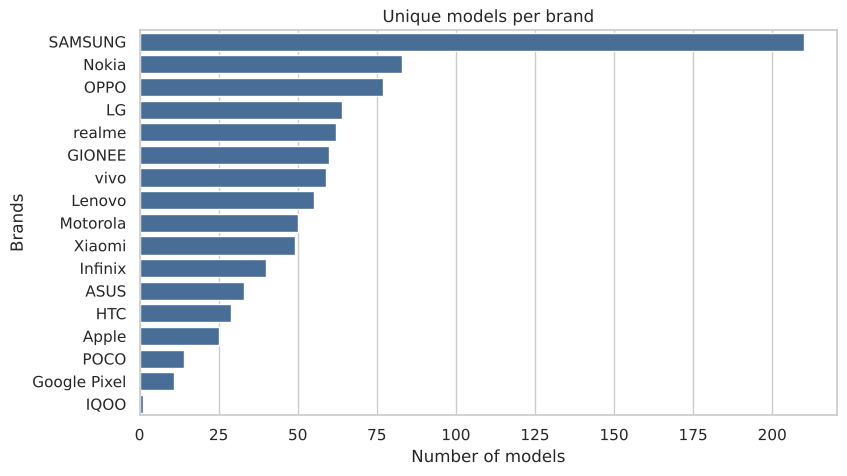

-> SAMSUNG has the most models (210).


In [4]:
q1 = d.groupby('Brands')['Models'].nunique().sort_values(ascending=False)
display(q1.rename('Unique models').to_frame())
plt.figure(figsize=(9,5)); sns.barplot(x=q1.values,y=q1.index,color='#3b6ea5')
plt.title('Unique models per brand'); plt.xlabel('Number of models'); plt.show()
print(f'-> {q1.index[0]} has the most models ({q1.iloc[0]}).')

## Q2. Top 10 mobile models by selling price

,Brands,Models,Selling Price
1,Apple,iPhone 13 Pro Max,179900
2,SAMSUNG,Fold 2 5G,169999
3,Apple,iPhone 13 Pro,169900
4,SAMSUNG,Galaxy Z Fold3 5G,157999
5,Apple,iPhone 11 Pro Max,150800
6,SAMSUNG,Galaxy Fold 2,149999
7,Apple,iPhone 12 Pro Max,149900
8,Apple,iPhone XS Max,144900
9,Apple,iPhone 11 Pro,140300
10,Apple,iPhone 12 Pro,139900


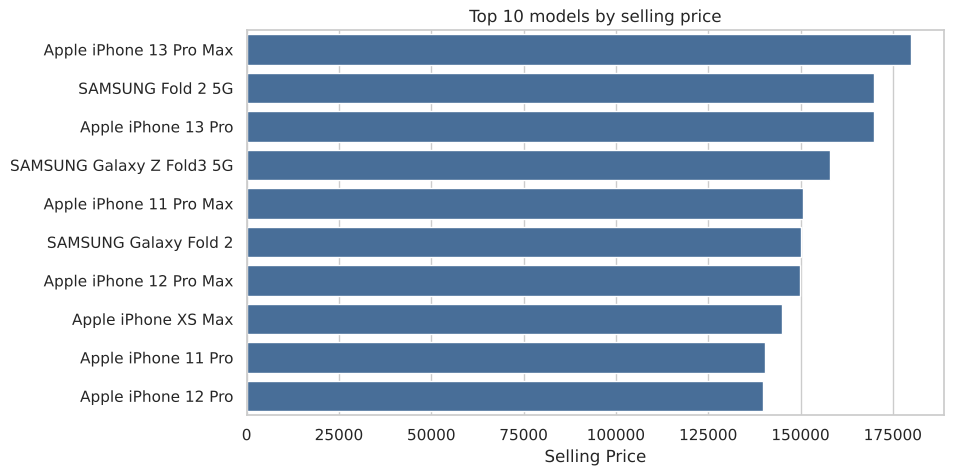

In [5]:
q2 = (d.groupby(['Brands','Model_Key'])['Selling Price'].max().sort_values(ascending=False).head(10).reset_index().rename(columns={'Model_Key':'Models'}))
name=d.drop_duplicates('Model_Key').set_index('Model_Key')['Models']; q2['Models']=q2['Models'].map(name)
q2.index += 1; display(q2)
plt.figure(figsize=(9,5)); sns.barplot(data=q2,x='Selling Price',y=q2['Brands']+' '+q2['Models'],color='#3b6ea5')
plt.title('Top 10 models by selling price'); plt.ylabel(''); plt.show()

(Each model can appear in several colours / variants; the highest price per model is used.)

## Q3. Average selling price per brand

,Avg selling price
Brands,
Apple,"85,963.08"
Google Pixel,"61,391.86"
IQOO,"37,190.00"
HTC,"28,314.38"
SAMSUNG,"24,248.14"
vivo,"23,866.24"
ASUS,"20,367.32"
LG,"19,323.18"
OPPO,"18,493.18"


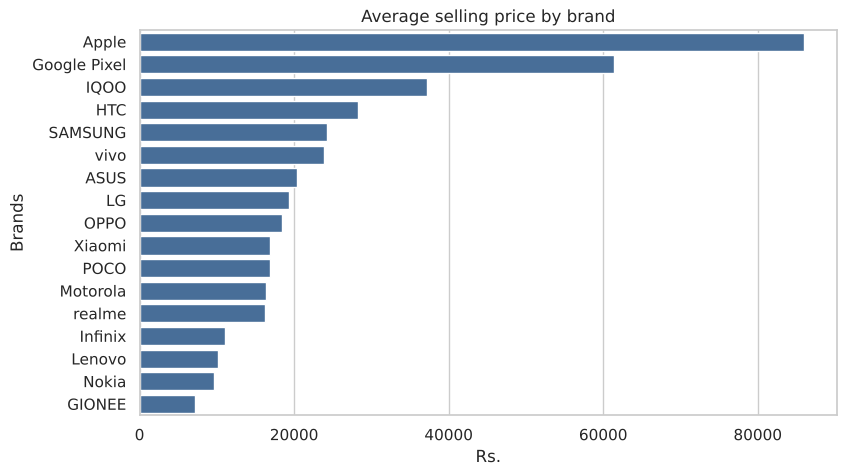

In [6]:
q3 = d.groupby('Brands')['Selling Price'].mean().sort_values(ascending=False)
display(q3.rename('Avg selling price').to_frame())
plt.figure(figsize=(9,5)); sns.barplot(x=q3.values,y=q3.index,color='#3b6ea5')
plt.title('Average selling price by brand'); plt.xlabel('Rs.'); plt.show()

## Q4. Which brand offers the highest average discount?

,Avg_Discount,Avg_Discount_Pct
Brands,,
Motorola,"4,288.55",12.54
IQOO,"3,800.00",9.07
LG,"3,044.60",8.72
Apple,"2,874.03",3.53
POCO,"2,614.86",14.35
SAMSUNG,"2,549.80",5.84
OPPO,"2,094.17",9.21
vivo,"1,696.66",5.68
realme,"1,437.59",8.67


Highest avg discount (amount): Motorola | (percent): POCO


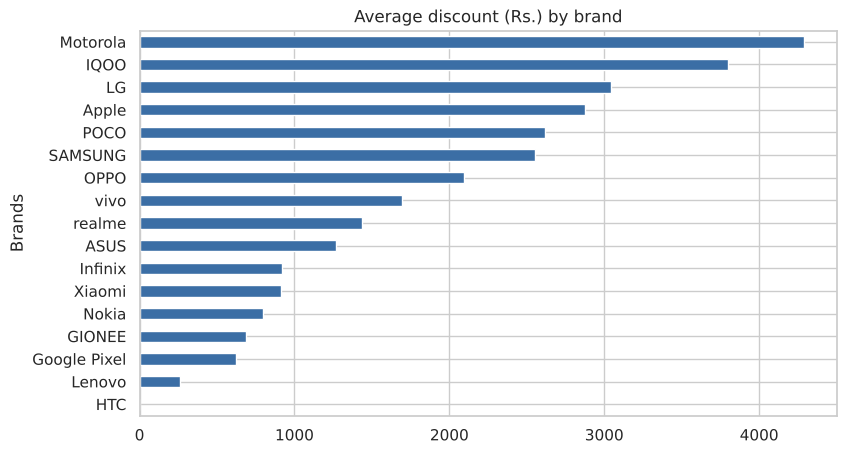

In [7]:
q4 = d.groupby('Brands').agg(Avg_Discount=('Discount','mean'),Avg_Discount_Pct=('Discount_Pct','mean')).sort_values('Avg_Discount',ascending=False)
display(q4)
print('Highest avg discount (amount):', q4['Avg_Discount'].idxmax(), '| (percent):', q4['Avg_Discount_Pct'].idxmax())
q4['Avg_Discount'].plot.barh(figsize=(9,5),color='#3b6ea5').invert_yaxis(); plt.title('Average discount (Rs.) by brand'); plt.show()

## Q5. Brands with the highest average customer rating vs. their average selling price

,Avg_Rating,Avg_Price,Models
Brands,,,
Apple,4.51,"85,963.08",25
Google Pixel,4.51,"61,391.86",11
IQOO,4.40,"37,190.00",1
POCO,4.39,"16,870.62",14
realme,4.38,"16,261.40",62
vivo,4.37,"23,866.24",59
Xiaomi,4.30,"16,941.91",49
OPPO,4.29,"18,493.18",77
Infinix,4.28,"11,099.47",40


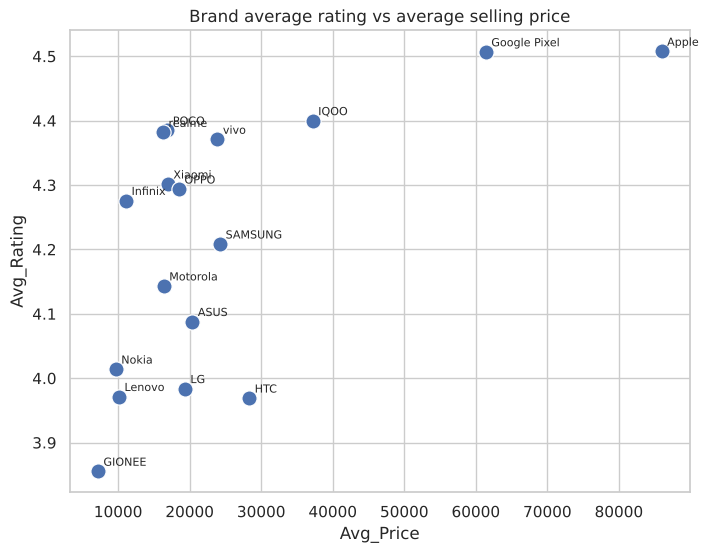

Correlation (brand level) rating vs price: 0.61


In [8]:
q5 = d.groupby('Brands').agg(Avg_Rating=('Rating','mean'),Avg_Price=('Selling Price','mean'),Models=('Models','nunique')).sort_values('Avg_Rating',ascending=False)
display(q5)
plt.figure(figsize=(8,6)); sns.scatterplot(data=q5,x='Avg_Price',y='Avg_Rating',s=120)
for b,r in q5.iterrows(): plt.annotate(b,(r.Avg_Price,r.Avg_Rating),xytext=(4,4),textcoords='offset points',fontsize=8)
plt.title('Brand average rating vs average selling price'); plt.show()
print('Correlation (brand level) rating vs price: %.2f' % q5['Avg_Rating'].corr(q5['Avg_Price']))

## Q6. Effect of storage capacity on average selling price

,Avg_Price,Median_Price,Count
Storage_Group,,,
4.00,"5,665.15","4,695.00",84
8.00,"8,123.29","6,985.00",138
16.00,"12,224.74","8,499.00",333
32.00,"14,190.23","9,999.00",550
64.00,"20,665.44","13,999.00",754
128.00,"30,190.47","21,970.00",752
256.00,"66,223.22","64,900.00",222
512.00,"119,964.90","139,900.00",63


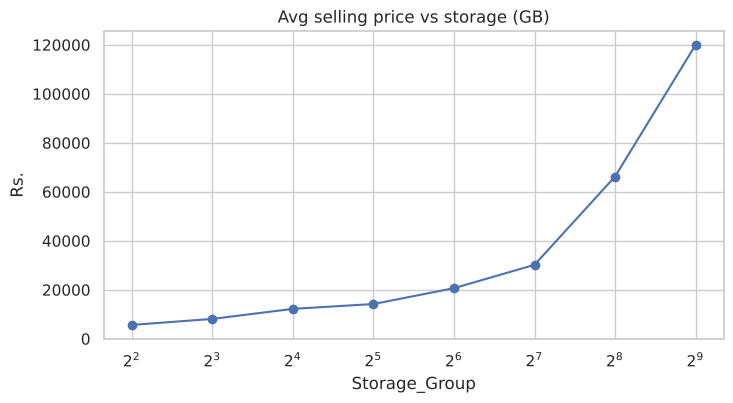

Correlation storage vs price (all rows): 0.64


In [9]:
d['Storage_Group'] = d['Storage'].where(d['Storage'].isin([4,8,16,32,64,128,256,512]))  # standard sizes
q6 = d.groupby('Storage_Group').agg(Avg_Price=('Selling Price','mean'),Median_Price=('Selling Price','median'),Count=('Selling Price','size'))
display(q6)
q6['Avg_Price'].plot(marker='o',figsize=(8,4)); plt.xscale('log',base=2); plt.title('Avg selling price vs storage (GB)'); plt.ylabel('Rs.'); plt.show()
print('Correlation storage vs price (all rows): %.2f' % d['Storage'].corr(d['Selling Price']))

Prices rise steadily with storage; the jump is especially large from 128 GB to 256 GB and beyond (premium/flagship devices).

## Q7. Models with the highest discount amount and their discount percentage

In [10]:
q7 = (d.sort_values('Discount',ascending=False).drop_duplicates(['Brands','Models'])
        [['Brands','Models','Original Price','Selling Price','Discount','Discount_Pct']].head(10).reset_index(drop=True))
q7.index += 1; display(q7)

,Brands,Models,Original Price,Selling Price,Discount,Discount_Pct
1,Motorola,Razr,149999,74999,75000,50.00
2,Motorola,Razr 5G,149999,89999,60000,40.00
3,ASUS,ROG,83999,26499,57500,68.45
4,LG,Wing,80000,29999,50001,62.50
5,Apple,iPhone XS Max,124900,78999,45901,36.75
6,LG,G8X,70000,27990,42010,60.01
7,SAMSUNG,Galaxy Fold 2,189999,149999,40000,21.05
8,SAMSUNG,Galaxy Note 8,74000,34899,39101,52.84
9,SAMSUNG,Galaxy S6 Edge+,61988,28000,33988,54.83
10,LG,G6,55000,22990,32010,58.20


## Q8. Best memory + storage combination (price vs. rating balance)

,Memory_GB,Storage,Avg_Price,Avg_Rating,Count,Rating_per_10k,Balance_Score
26,6.00,64,"20,087.16",4.29,128,2.14,0.50
23,4.00,128,"33,097.65",4.37,135,1.32,0.50
21,4.00,64,"19,131.51",4.28,553,2.24,0.49
36,8.00,128,"29,988.61",4.34,251,1.45,0.48
16,3.00,64,"26,950.15",4.31,48,1.60,0.46
28,6.00,128,"26,661.17",4.30,317,1.61,0.45
9,2.00,32,"12,964.81",4.21,125,3.25,0.44
39,8.00,256,"41,820.80",4.37,74,1.05,0.44
15,3.00,32,"12,865.98",4.16,340,3.24,0.38
19,3.00,256,"88,455.56",4.59,18,0.52,0.37


-> Best balance: 6 GB RAM + 64 GB storage (avg price Rs.20,087, rating 4.29)


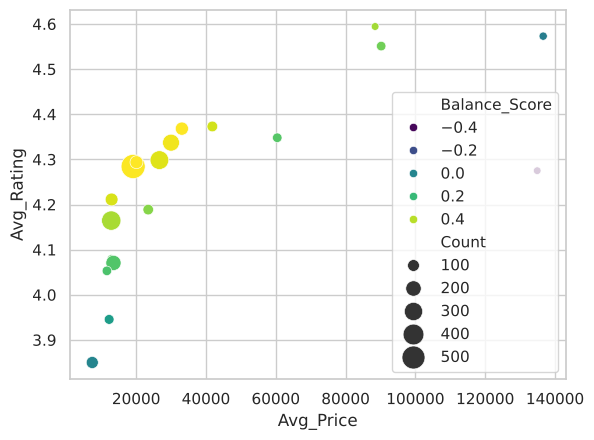

In [11]:
combo = d[d['Is_Smartphone']].groupby(['Memory_GB','Storage']).agg(Avg_Price=('Selling Price','mean'),Avg_Rating=('Rating','mean'),Count=('Rating','size')).reset_index()
combo = combo[combo['Count']>=15].copy()          # ignore rare combinations
combo['Rating_per_10k'] = combo['Avg_Rating']/(combo['Avg_Price']/10000)
# balance score = normalised rating - normalised price (high rating, low price)
mm=lambda s:(s-s.min())/(s.max()-s.min())
combo['Balance_Score'] = mm(combo['Avg_Rating']) - mm(combo['Avg_Price'])
display(combo.sort_values('Balance_Score',ascending=False).head(10))
best = combo.loc[combo['Balance_Score'].idxmax()]
print(f"-> Best balance: {best.Memory_GB:g} GB RAM + {best.Storage:g} GB storage (avg price Rs.{best.Avg_Price:,.0f}, rating {best.Avg_Rating:.2f})")
sns.scatterplot(data=combo,x='Avg_Price',y='Avg_Rating',size='Count',hue='Balance_Score',palette='viridis',sizes=(30,300)); plt.show()

**Method:** only smartphones (RAM ≥ 1 GB, storage ≥ 8 GB, price ≥ Rs. 3,000) and combinations with ≥15 phones are considered. Balance score = min-max normalised average rating − min-max normalised average price, so a high score means a high rating at a low price.

## Q9. Top 10 best value-for-money models

In [12]:
v = d[d['Is_Smartphone']].copy()   # smartphones only (feature phones have unreliable RAM/storage data)
mm=lambda s:(s-s.min())/(s.max()-s.min())
# components scaled 0-1 (price inverted: cheaper = better)
v['s_price']   = 1 - mm(np.log(v['Selling Price']))
v['s_disc']    = mm(v['Discount_Pct'].clip(upper=v['Discount_Pct'].quantile(.99)))
v['s_storage'] = mm(np.log2(v['Storage']))
v['s_memory']  = mm(np.log2(v['Memory_GB']))
v['s_rating']  = mm(v['Rating'])
w = {'s_price':0.30,'s_rating':0.25,'s_storage':0.15,'s_memory':0.15,'s_disc':0.15}
v['Value_Score'] = sum(v[k]*x for k,x in w.items())*100
q9 = (v.sort_values('Value_Score',ascending=False).drop_duplicates(['Brands','Model_Key'])
        [['Brands','Models','Memory_GB','Storage','Selling Price','Discount_Pct','Rating','Value_Score']].head(10).reset_index(drop=True))
q9.index += 1; display(q9)

,Brands,Models,Memory_GB,Storage,Selling Price,Discount_Pct,Rating,Value_Score
1,OPPO,F11 Pro,6.00,128,14990,50.02,4.50,73.89
2,Nokia,RM-1172 / Nokia 230 DS,16.00,256,4196,0.00,4.00,71.71
3,SAMSUNG,Galaxy J6,4.00,64,9490,44.53,4.50,71.02
4,vivo,V20 2021,12.00,256,15490,20.52,4.40,70.12
5,Motorola,G7,4.00,64,9999,47.37,4.30,69.62
6,ASUS,ROG,8.00,128,26499,68.45,4.30,69.28
7,Nokia,7 Plus,4.00,64,12000,53.90,4.30,69.03
8,vivo,V21 5G,8.00,256,15490,20.52,4.50,68.85
9,SAMSUNG,Galaxy A8 Star,6.00,64,16989,55.28,4.30,68.59
10,LG,W41 Pro,6.00,128,10499,47.50,3.70,68.43


**How the Value Score is calculated** (0–100): every factor is min-max scaled to 0–1 and combined with weights  
`Value = 100 × (0.30·Price_score + 0.25·Rating + 0.15·Storage + 0.15·Memory + 0.15·Discount%)`  
- *Price_score* = 1 − scaled log(selling price) (cheaper is better); storage & memory use log₂ so doubling counts equally;  
- discount % is capped at the 99th percentile to limit outliers. Weights are a judgement call and can be changed in the cell above.

## Q10. What determines a "Good Product"?

The dataset has no explicit *Good Product* column, so it is defined from customer rating: **Good Product = Rating ≥ 4.1** (i.e. rating bucket `R` = 5). 
Rating itself is therefore **excluded** from the predictors (it would leak the answer); we test price, discount, discount %, memory and storage.

Good_Product
1   0.80
0   0.20
Name: proportion, dtype: float64


,Pearson,Spearman
Storage,0.29,0.42
Memory_GB,0.30,0.37
Selling Price,0.22,0.35
Discount,0.07,0.20
Discount_Pct,0.07,0.18


,LogReg_coef(std),RF_importance
Selling Price,0.62,0.43
Storage,1.55,0.24
Memory_GB,0.35,0.20
Discount,-0.37,0.06
Discount_Pct,0.21,0.06


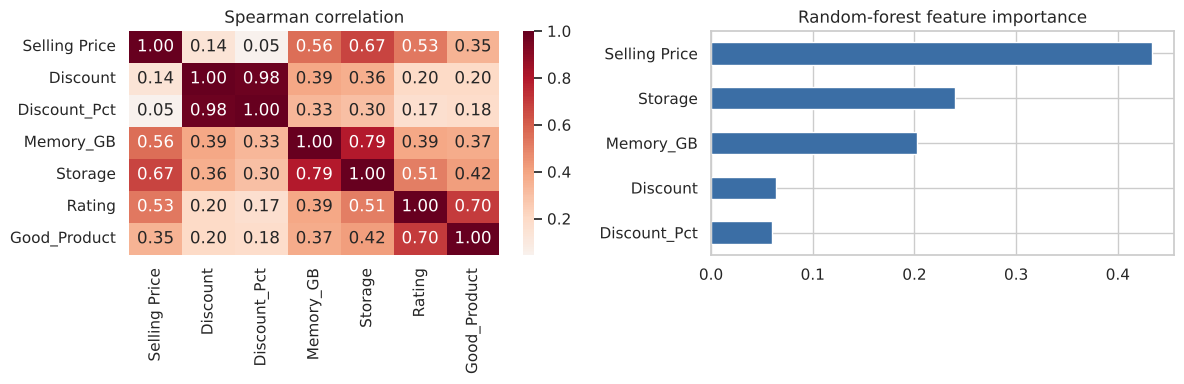

Good-product rate by brand (top/bottom):


,Good rate
Brands,
GIONEE,0.27
HTC,0.29
LG,0.37
POCO,1.00
Apple,1.00
realme,1.00


In [13]:
g = d.copy(); g['Good_Product'] = (g['Rating']>=4.1).astype(int)
print(g['Good_Product'].value_counts(normalize=True).round(3))
feats = ['Selling Price','Discount','Discount_Pct','Memory_GB','Storage']
# 1) correlation with the target (point-biserial) + Spearman
corr = pd.DataFrame({'Pearson':g[feats].corrwith(g['Good_Product']),
                     'Spearman':g[feats].corrwith(g['Good_Product'],method='spearman')}).sort_values('Spearman',key=abs,ascending=False)
display(corr)
# 2) standardised logistic-regression coefficients + random-forest importance
X = StandardScaler().fit_transform(g[feats]); y=g['Good_Product']
lr = LogisticRegression(max_iter=1000).fit(X,y)
rf = RandomForestClassifier(300,random_state=0,min_samples_leaf=5).fit(g[feats],y)
imp = pd.DataFrame({'LogReg_coef(std)':lr.coef_[0],'RF_importance':rf.feature_importances_},index=feats).sort_values('RF_importance',ascending=False)
display(imp)
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.heatmap(g[feats+['Rating','Good_Product']].corr(method='spearman'),annot=True,fmt='.2f',cmap='RdBu_r',center=0,ax=ax[0]); ax[0].set_title('Spearman correlation')
imp['RF_importance'].plot.barh(ax=ax[1],color='#3b6ea5').invert_yaxis(); ax[1].set_title('Random-forest feature importance'); plt.tight_layout(); plt.show()
print('Good-product rate by brand (top/bottom):'); r=g.groupby('Brands')['Good_Product'].mean().sort_values(); display(pd.concat([r.head(3),r.tail(3)]).to_frame('Good rate'))

## Summary of findings
1. **Samsung** has the most models (211), followed by Nokia (83) and OPPO (77).
2. The most expensive models are Apple iPhone 13 Pro Max / 13 Pro and Samsung Fold devices (up to Rs. 1.8 lakh).
3. **Apple** has the highest average selling price, then Google Pixel; Gionee and Nokia are the cheapest.
4. **Motorola** gives the highest average discount in rupees; **POCO** the highest in percentage terms.
5. Apple and Google Pixel have the highest average rating (~4.5) – and also the highest prices; across brands rating and price are positively correlated (~0.6).
6. Average price rises steadily with storage, and sharply from 128 GB to 256 GB and above.
7. Largest discounts: Motorola Razr, Razr 5G, ASUS ROG, LG Wing (see Q7 table for percentages).
8. The best price/rating balance is **6 GB RAM + 64 GB storage** (~Rs. 20k, rating ~4.29); 4 GB + 64 GB and 4 GB + 128 GB are close behind.
9. Value-for-money ranking is produced by the weighted Value Score in Q9.
10. For "Good Product" (rating ≥ 4.1), **storage, memory and selling price** have the strongest relationship; discount is the weakest.

*(Numbers in this summary were read from the executed outputs above; re-check them if the data or assumptions change.)*